## Hotdog -- no hotdog
This is the poster hand-in project for the course. Please see the associated PDF for instructions.

In [2]:
import os
import numpy as np
import glob
import PIL.Image as Image
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

We always check that we are running on a GPU

In [3]:
if torch.cuda.is_available():
    device = torch.device('cuda')
    print("The code will run on GPU (CUDA).")
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    print("The code will run on Apple GPU (MPS).")
else:
    device = torch.device('cpu')
    print("The code will run on CPU.")

The code will run on Apple GPU (MPS).


We provide you with a class that can load the *hotdog/not hotdog* dataset you should use from /dtu/datasets1/02516/

In [4]:
class Hotdog_NotHotdog(torch.utils.data.Dataset):
    def __init__(self, train, transform, data_path='/dtu/datasets1/02516/hotdog_nothotdog'):
        'Initialization'
        self.transform = transform
        data_path = os.path.join(data_path, 'train' if train else 'test')
        image_classes = [os.path.split(d)[1] for d in glob.glob(data_path +'/*') if os.path.isdir(d)]
        image_classes.sort()
        self.name_to_label = {c: id for id, c in enumerate(image_classes)}
        self.image_paths = glob.glob(data_path + '/*/*.jpg')

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        c = os.path.split(os.path.split(image_path)[0])[1]
        y = self.name_to_label[c]
        X = self.transform(image)
        return X, y

Below is the simple way of converting the images to something that can be fed through a network.
Feel free to use something other than $128\times128$ images.

In [5]:
size = 128
train_transform = transforms.Compose([transforms.Resize((size, size)), 
                                    transforms.ToTensor()])
test_transform = transforms.Compose([transforms.Resize((size, size)), 
                                    transforms.ToTensor()])

data_path = '/dtu/datasets1/02516/hotdog_nothotdog'
if not os.path.isdir(data_path):
    data_path = os.path.join('..', 'data', 'hotdog_nothotdog')
if not os.path.isdir(data_path):
    data_path = os.path.join('data', 'hotdog_nothotdog')
print('Using data_path:', os.path.abspath(data_path))

batch_size = 64
trainset = Hotdog_NotHotdog(train=True, transform=train_transform, data_path=data_path)
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = Hotdog_NotHotdog(train=False, transform=test_transform, data_path=data_path)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)
print(f'Train images: {len(trainset)}, test images: {len(testset)}')

Using data_path: /Users/starrift/Documents/Deeplearning/course_cv/data/hotdog_nothotdog
Train images: 2047, test images: 1862


Let's look at some images from our data 

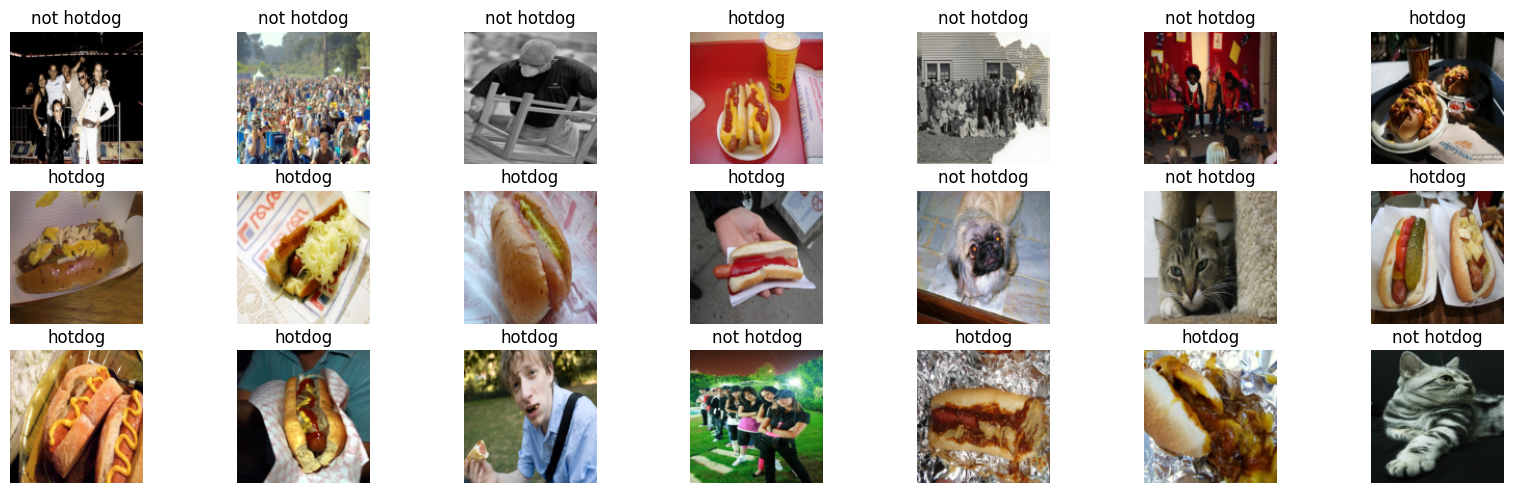

In [6]:
images, labels = next(iter(train_loader))
plt.figure(figsize=(20,10))

for i in range(21):
    plt.subplot(5,7,i+1)
    plt.imshow(np.swapaxes(np.swapaxes(images[i].numpy(), 0, 2), 0, 1))
    plt.title(['hotdog', 'not hotdog'][labels[i].item()])
    plt.axis('off')

    


## Baseline Vision
Now create a model and train it!

Baseline uses only Conv, ReLU, MaxPool and FC (same layer types as the group v1 baseline), one conv per stage, slightly wider channels, and Adam:
* channels $32 \rightarrow 64 \rightarrow 128$, three $2\times 2$ pools ($128\rightarrow 16$)
* flatten $16\times 16\times 128$ then `Linear(32768, 128)` $\rightarrow$ `Linear(128, 2)` logits (no Softmax)
* train with Adam (`lr=0.001`) for 6 epochs


In [ ]:
class HotdogBaselineCNN(nn.Module):
    """Same layer types as the group baseline (Conv / ReLU / MaxPool / FC),
    3-stage 128	o16 spatial size. Slightly wider than v1 (32-64-128 vs 16-32-64)."""
    def __init__(self, num_classes=2):
        super(HotdogBaselineCNN, self).__init__()

        self.convolutional = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )

        # 16 x 16 x 128 = 32768
        self.fully_connected = nn.Sequential(
            nn.Linear(16 * 16 * 128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        
        return x

We instantiate a copy of our network, transfer it to the GPU if it's available.
We also check if the dimensions of our network match.

In [8]:
model = HotdogBaselineCNN(num_classes=2)
model.to(device)
# Adam is what made the group v1 baseline reach ~72%; SGD 0.01 collapses this CNN (~50%)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

data = next(iter(train_loader))[0].to(device)
print('Shape of the output from the convolutional part', model.convolutional(data).shape)
print('Shape of the model output (logits)', model(data).shape)


# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,}")

# Test forward pass with a dummy batch on device
dummy_x = torch.randn(4, 3, 128, 128, device=device)
dummy_out = model(dummy_x)
print(f"Test forward pass output shape: {dummy_out.shape}  (batch_size=4, num_classes=2)")

Trainable parameters: 4,287,938
Shape of the output from the convolutional part torch.Size([64, 128, 16, 16])
Shape of the model output (logits) torch.Size([64, 2])
Total Trainable Parameters: 4,287,938
Test forward pass output shape: torch.Size([4, 2])  (batch_size=4, num_classes=2)


We train this network for 12 epochs with Adam and record the training curve.

In [9]:
num_epochs = 10
train_accs, test_accs, train_losses = [], [], []
best_test_acc = 0.0

for epoch in tqdm(range(num_epochs), unit='epoch'):
    model.train()
    train_correct = 0
    running_loss = 0.0
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()
        running_loss += loss.item() * data.size(0)

    model.eval()
    test_correct = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1)
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    epoch_loss = running_loss / len(trainset)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    train_losses.append(epoch_loss)
    best_test_acc = max(best_test_acc, test_acc)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%\t loss: {loss:.4f}".format(
        test=100*test_acc, train=100*train_acc, loss=epoch_loss))

print(f"Final test accuracy: {100*test_accs[-1]:.1f}%")
print(f"Best test accuracy:  {100*best_test_acc:.1f}%")

  0%|          | 0/10 [00:00<?, ?epoch/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 47.2%	 test: 51.9%	 loss: 0.8361


  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 47.5%	 test: 51.9%	 loss: 0.8384


  0%|          | 0/32 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 47.5%	 test: 51.9%	 loss: 0.8384


  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 47.5%	 test: 51.9%	 loss: 0.8384
Final test accuracy: 51.9%
Best test accuracy:  51.9%


## Squish vs keep-aspect-ratio crop

The course PDF notes that `Resize((128, 128))` forces a square by **squishing** non-square photos, and that this is not necessarily best. We keep the same `HotdogBaselineCNN` + Adam and compare:

* **Squish:** `Resize((128, 128))` — stretches/compresses the whole image (this is also our baseline transform).
* **Crop:** `Resize(128)` then `CenterCrop(128)` — keeps aspect ratio, may cut off the edges.

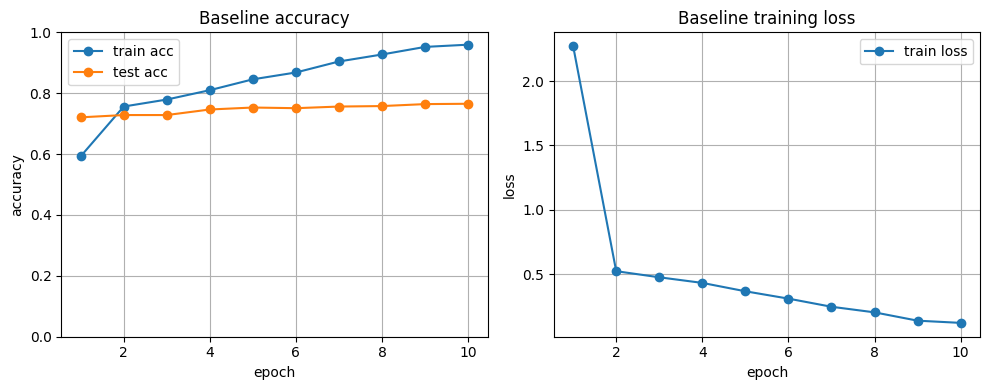

In [10]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_accs, marker='o', label='train acc')
plt.plot(range(1, num_epochs + 1), test_accs, marker='o', label='test acc')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title('Baseline accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_losses, marker='o', label='train loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.title('Baseline training loss')

plt.tight_layout()
plt.show()

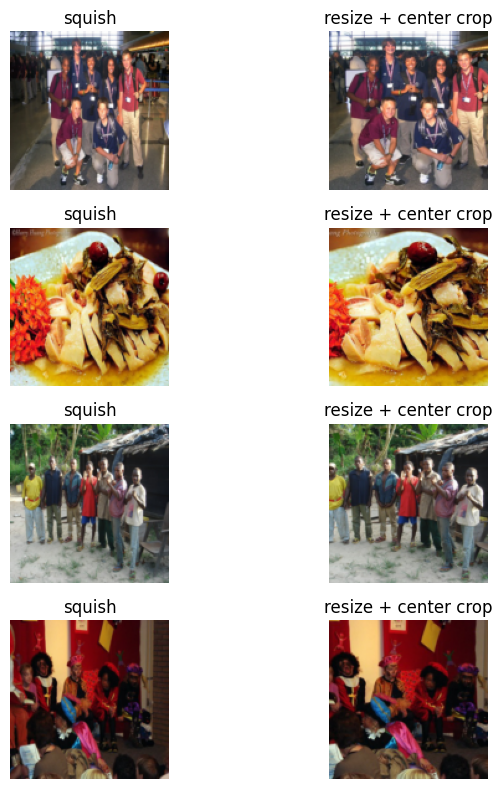

In [11]:
squish_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
])

#Shrink the shorter side to 128, and scale the other side accordingly while maintaining the original aspect ratio of the image.
crop_transform = transforms.Compose([
    transforms.Resize(size),  # shrink the shorter side to 128
    transforms.CenterCrop(size),  # crop the center 128x128, scale the other side accordingly while maintaining the original aspect ratio of the image.
    transforms.ToTensor(),
])

# Visual check: same files, two ways of making a 128x128 tensor
sample_paths = trainset.image_paths[:4]
plt.figure(figsize=(8, 8))
for i, path in enumerate(sample_paths):
    img = Image.open(path).convert('RGB')
    plt.subplot(4, 2, 2 * i + 1)
    plt.imshow(squish_transform(img).permute(1, 2, 0))
    plt.title('squish')
    plt.axis('off')
    plt.subplot(4, 2, 2 * i + 2)
    plt.imshow(crop_transform(img).permute(1, 2, 0))
    plt.title('resize + center crop')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [12]:
def make_loaders(transform):
    tr = Hotdog_NotHotdog(train=True, transform=transform, data_path=data_path)
    te = Hotdog_NotHotdog(train=False, transform=transform, data_path=data_path)
    tr_loader = DataLoader(tr, batch_size=batch_size, shuffle=True, num_workers=0)
    te_loader = DataLoader(te, batch_size=batch_size, shuffle=False, num_workers=0)
    return tr, te, tr_loader, te_loader


def train_same_baseline(tr_loader, te_loader, tr_set, te_set, epochs, model_cls=HotdogBaselineCNN):
    net = model_cls(num_classes=2).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    history = {'train_acc': [], 'test_acc': [], 'train_loss': []}
    best = 0.0
    for epoch in tqdm(range(epochs), unit='epoch'):
        net.train()
        train_correct = 0
        running_loss = 0.0
        for data, target in tr_loader:
            data, target = data.to(device), target.to(device)
            opt.zero_grad()
            output = net(data)
            loss = crit(output, target)
            loss.backward()
            opt.step()
            train_correct += (output.argmax(1) == target).sum().item()
            running_loss += loss.item() * data.size(0)
        net.eval()
        test_correct = 0
        with torch.no_grad():
            for data, target in te_loader:
                data, target = data.to(device), target.to(device)
                output = net(data)
                test_correct += (output.argmax(1) == target).sum().item()
        train_acc = train_correct / len(tr_set)
        test_acc = test_correct / len(te_set)
        epoch_loss = running_loss / len(tr_set)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['train_loss'].append(epoch_loss)
        best = max(best, test_acc)
        print(f'epoch {epoch+1}/{epochs}  train {100*train_acc:.1f}%  test {100*test_acc:.1f}%  loss {epoch_loss:.4f}')
    history['best_test'] = best
    history['final_test'] = history['test_acc'][-1]
    return net, history

In [13]:
resize_epochs = num_epochs  # same length as the baseline run above

print('=== SQUISH: Resize((128, 128)) ===')
squish_train, squish_test, squish_tr_loader, squish_te_loader = make_loaders(squish_transform)
_, hist_squish = train_same_baseline(
    squish_tr_loader, squish_te_loader, squish_train, squish_test, resize_epochs)

print('\n=== CROP: Resize(128) + CenterCrop(128) ===')
crop_train, crop_test, crop_tr_loader, crop_te_loader = make_loaders(crop_transform)
_, hist_crop = train_same_baseline(
    crop_tr_loader, crop_te_loader, crop_train, crop_test, resize_epochs)

print('\n=== Comparison (same CNN, Adam, epochs) ===')
print(f"Squish  final test {100*hist_squish['final_test']:.1f}%  best {100*hist_squish['best_test']:.1f}%")
print(f"Crop    final test {100*hist_crop['final_test']:.1f}%  best {100*hist_crop['best_test']:.1f}%")

=== SQUISH: Resize((128, 128)) ===


  0%|          | 0/10 [00:00<?, ?epoch/s]

epoch 1/10  train 57.8%  test 63.5%  loss 3.1131
epoch 2/10  train 70.8%  test 70.9%  loss 0.5757
epoch 3/10  train 75.9%  test 71.5%  loss 0.5097
epoch 4/10  train 77.5%  test 72.0%  loss 0.4677
epoch 5/10  train 82.0%  test 71.9%  loss 0.4065
epoch 6/10  train 84.3%  test 72.8%  loss 0.3543
epoch 7/10  train 87.2%  test 72.6%  loss 0.2951
epoch 8/10  train 90.5%  test 72.0%  loss 0.2308
epoch 9/10  train 92.8%  test 72.8%  loss 0.1884
epoch 10/10  train 93.7%  test 74.0%  loss 0.1700

=== CROP: Resize(128) + CenterCrop(128) ===


  0%|          | 0/10 [00:00<?, ?epoch/s]

epoch 1/10  train 59.4%  test 70.0%  loss 1.3626
epoch 2/10  train 73.1%  test 72.3%  loss 0.5402
epoch 3/10  train 78.2%  test 73.8%  loss 0.4749
epoch 4/10  train 81.1%  test 73.1%  loss 0.4053
epoch 5/10  train 85.4%  test 72.9%  loss 0.3548
epoch 6/10  train 89.2%  test 74.2%  loss 0.2677
epoch 7/10  train 93.4%  test 75.2%  loss 0.1897
epoch 8/10  train 95.0%  test 74.1%  loss 0.1516
epoch 9/10  train 97.3%  test 74.0%  loss 0.0933
epoch 10/10  train 98.4%  test 74.0%  loss 0.0607

=== Comparison (same CNN, Adam, epochs) ===
Squish  final test 74.0%  best 74.0%
Crop    final test 74.0%  best 75.2%


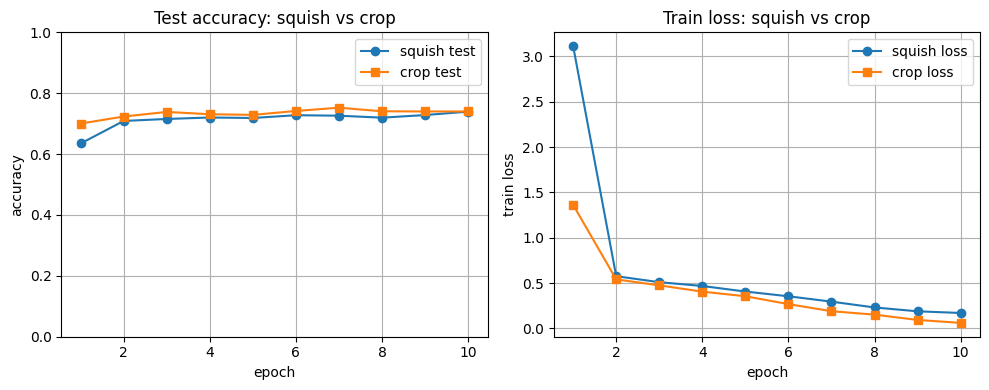

In [14]:
epochs_axis = range(1, resize_epochs + 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, hist_squish['test_acc'], marker='o', label='squish test')
plt.plot(epochs_axis, hist_crop['test_acc'], marker='s', label='crop test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title('Test accuracy: squish vs crop')

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, hist_squish['train_loss'], marker='o', label='squish loss')
plt.plot(epochs_axis, hist_crop['train_loss'], marker='s', label='crop loss')
plt.xlabel('epoch')
plt.ylabel('train loss')
plt.legend()
plt.grid(True)
plt.title('Train loss: squish vs crop')
plt.tight_layout()
plt.show()

## Batch normalization ablation

PDF question: *Did you use batch normalization? Does it improve the performance?*

We keep the **same** 3-stage CNN, Adam (`lr=0.001`), squish `128×128` loaders, and number of epochs. The only change is inserting `BatchNorm2d` after each convolution:

`Conv → BatchNorm → ReLU → MaxPool`

Conv layers use `bias=False` because BN already has a learnable shift. Training uses `model.train()` and testing uses `model.eval()` so BN uses batch statistics vs running averages.

In [15]:
class HotdogCNN_BN(nn.Module):
    def __init__(self, num_classes=2):
        super(HotdogCNN_BN, self).__init__()

        self.convolutional = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )

        self.fully_connected = nn.Sequential(
            nn.Linear(16 * 16 * 128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

# sanity check
_bn = HotdogCNN_BN().to(device)
_x = next(iter(train_loader))[0].to(device)
print('BN conv out', _bn.convolutional(_x).shape)
print('BN logits', _bn(_x).shape)
del _bn, _x

BN conv out torch.Size([64, 128, 16, 16])
BN logits torch.Size([64, 2])


In [16]:
print('=== Baseline (no BN), same squish loaders ===')
print(f"Already trained: final test {100*test_accs[-1]:.1f}%  best {100*best_test_acc:.1f}%")

print('\n=== With BatchNorm ===')
_, hist_bn = train_same_baseline(
    train_loader, test_loader, trainset, testset, num_epochs, model_cls=HotdogCNN_BN)

print('\n=== BN vs no BN ===')
print(f"No BN   final test {100*test_accs[-1]:.1f}%  best {100*best_test_acc:.1f}%")
print(f"With BN final test {100*hist_bn['final_test']:.1f}%  best {100*hist_bn['best_test']:.1f}%")

=== Baseline (no BN), same squish loaders ===
Already trained: final test 76.5%  best 76.5%

=== With BatchNorm ===


  0%|          | 0/10 [00:00<?, ?epoch/s]

epoch 1/10  train 63.3%  test 69.2%  loss 5.0250
epoch 2/10  train 74.0%  test 71.1%  loss 0.5430
epoch 3/10  train 80.0%  test 72.5%  loss 0.4470
epoch 4/10  train 77.7%  test 66.8%  loss 0.4966
epoch 5/10  train 82.4%  test 75.9%  loss 0.4090
epoch 6/10  train 85.3%  test 76.7%  loss 0.3556
epoch 7/10  train 86.9%  test 75.0%  loss 0.3244
epoch 8/10  train 86.6%  test 73.8%  loss 0.3197
epoch 9/10  train 87.5%  test 75.1%  loss 0.3042
epoch 10/10  train 91.0%  test 74.4%  loss 0.2466

=== BN vs no BN ===
No BN   final test 76.5%  best 76.5%
With BN final test 74.4%  best 76.7%


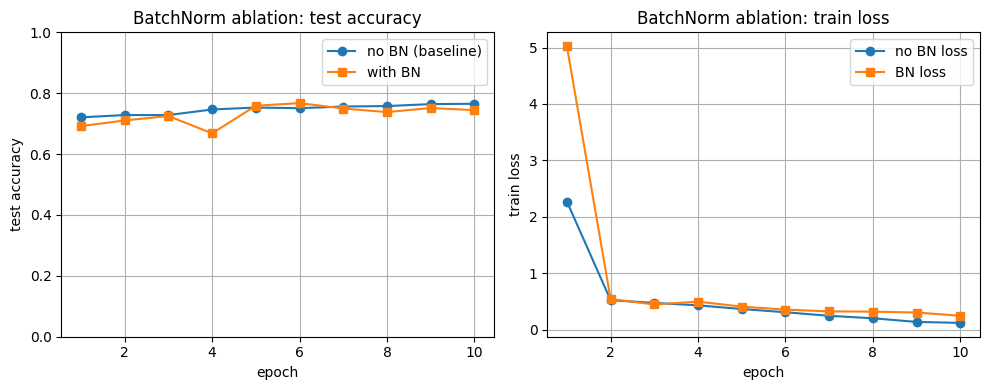

In [17]:
epochs_axis = range(1, num_epochs + 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, test_accs, marker='o', label='no BN (baseline)')
plt.plot(epochs_axis, hist_bn['test_acc'], marker='s', label='with BN')
plt.xlabel('epoch')
plt.ylabel('test accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title('BatchNorm ablation: test accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, train_losses, marker='o', label='no BN loss')
plt.plot(epochs_axis, hist_bn['train_loss'], marker='s', label='BN loss')
plt.xlabel('epoch')
plt.ylabel('train loss')
plt.legend()
plt.grid(True)
plt.title('BatchNorm ablation: train loss')
plt.tight_layout()
plt.show()

# Transfer Learning Version

In [18]:
import torch
import glob
import numpy as np
import PIL.Image as Image
from tqdm.notebook import tqdm

import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt

# priority -> cuda -> mps -> cpu
if torch.cuda.is_available():
    device = torch.device("cude")
    print("The code will run on GPU (CUDA).")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("The code will run on Apple GPU (MPS).")
else:
    device = torch.device("cpu")
    print("The code will run on CPU.")

The code will run on Apple GPU (MPS).


In [19]:
# data set ： 从文件读jpg'

class Hotdog_NotHotdog(Dataset):
    def __init__(self, train, transform, data_path):
        self.transform = transform
        # train=true 读train子文件夹，否则读test
        split_dir = os.path.join(data_path, 'train' if train else 'test')
        image_classes = [
            os.path.split(d)[1]  
            for d in glob.glob(split_dir + '/*')
            if os.path.isdir(d)
        ]
        image_classes.sort()
        self.name_to_label = {c: i for i, c in enumerate(image_classes)}
        self.image_paths = glob.glob(split_dir + '/*/*.jpg')

    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert("RGB")  # 保证 3 通道
        class_name = os.path.split(os.path.split(image_path)[0])[1]
        y = self.name_to_label[class_name]             # 整数标签，0 或 1
        x = self.transform(image)                      # PIL -> Tensor
        return x, y
        

In [20]:
# data path
data_path = '/dtu/datasets1/02516/hotdog_nothotdog'
if not os.path.isdir(data_path):
    data_path = os.path.join('..', 'data', 'hotdog_nothotdog')
if not os.path.isdir(data_path):
    data_path = os.path.join('data', 'hotdog_nothotdog')
print('Using data_path:', os.path.abspath(data_path))

Using data_path: /Users/starrift/Documents/Deeplearning/course_cv/data/hotdog_nothotdog


In [25]:
# Transfer Learning special processing

# pretrained ResNet uses this set of mean/std on the ImageNet dataset
# the order must be Resize -> ToTensor -> Normalize
# For ToTensor, devided pixels by 255 to scale to [0, 1]
# For Normalize, ( x - mean ) / std, perform it separately from 3 RGB channels

imagent_mean = [0.485, 0.456, 0.406]
imagent_std = [0.229, 0.224, 0.225]
size_tl = 128
batch_size = 64
num_epochs_tl = 5
lr_tl = 1e-4

train_transform_tl = transforms.Compose([
    transforms.Resize((size_tl, size_tl)),
    
    # data augmentation
    transforms.RandomHorizontalFlip(p = 0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),
    transforms.Normalize(imagent_mean, imagent_std),
])
test_transform_tl = transforms.Compose([
    transforms.Resize((size_tl, size_tl)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagent_mean, std=imagent_std),
])

trainset_tl = Hotdog_NotHotdog(train = True, transform = train_transform_tl, data_path = data_path)
testset_tl = Hotdog_NotHotdog(train = False, transform = test_transform_tl, data_path = data_path)

train_loader_tl = DataLoader(transet_tl, batch_size = batch_size, shuffle = True, num_workers = 0)
test_loader_tl = DataLoader(testset_tl, batch_size = batch_size, shuffle = False, num_workers = 0)
print(f"Train images: {len(trainset_tl)}, test images: {len(testset_tl)}")
print("Classes:", trainset_tl.name_to_label)




Train images: 2047, test images: 1862
Classes: {'hotdog': 0, 'nothotdog': 1}


In [31]:
# Load the pretrained ResNet18 and replace it with a 2 class head

# weights = DEFAULT, download the weights of ImageNet

# Convolustional layers can already extract edges, textures and object parts

model_resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 原来的最后一层：Linear(512, 1000)，对应 ImageNet 1000 类
# in_features=512：全局平均池化之后的向量长度

in_features = model_resnet.fc.in_features
# 换成作业的 2 类头：hotdog / not-hotdog
# 新头是随机初始化的；前面卷积仍是 ImageNet 权重
model_resnet.fc = nn.Linear(in_features, 2)
model_resnet = model_resnet.to(device)

print(model_resnet.fc)

Linear(in_features=512, out_features=2, bias=True)


In [33]:
# ---------- 6) Loss function + optimizer ----------

# CrossEntropyLoss = 内部 log-softmax + NLL，所以网络输出必须是 logits（不要再接 Softmax）
criterion_tl = nn.CrossEntropyLoss()

# parameters() : convonlutional
optimizer_tl = torch.optim.Adam(model_resnet.parameters(), lr = lr_tl)

# ---------- 7) 训练 + 验证 ----------
train_accs_tl, test_accs_tl, train_losses_tl = [], [], []
best_test_acc_tl = 0.0

print(f"Start: ResNet-18 transfer, Adam lr={lr_tl}, epochs={num_epochs_tl}")

for epoch in tqdm(range(num_epochs_tl), unit='epoch'):
    model_resnet.train()
    train_correct = 0
    running_loss = 0.0

    for data, target in tqdm(train_loader_tl, total=len(train_loader_tl)):
        data, target = data.to(device), target.to(device)

        optimizer_tl.zero_grad()       # 必须清梯度，否则会累加
        logits = model_resnet(data)    # [batch, 2]
        loss = criterion_tl(logits, target)
        loss.backward()                # 反传，算出每个可训练参数的梯度
        optimizer_tl.step()            # 按梯度、用小 lr 改权重

        pred = logits.argmax(dim=1)    # 两个 logit 里谁大，就是预测类
        train_correct += (pred == target).sum().cpu().item()
        running_loss += loss.item() * data.size(0)

# eval(): BN 改用训练期间积累的 running mean/var
    model_resnet.eval()
    test_correct = 0
    with torch.no_grad():
        for data, target in test_loader_tl:
            data, target = data.to(device), target.to(device)
            logits = model_resnet(data)
            pred = logits.argmax(dim=1)
            test_correct += (pred == target).sum().cpu().item()



    train_acc = train_correct / len(trainset_tl)
    test_acc = test_correct / len(testset_tl)
    epoch_loss = running_loss / len(trainset_tl)

    train_accs_tl.append(train_acc)
    test_accs_tl.append(test_acc)
    train_losses_tl.append(epoch_loss)
    best_test_acc_tl = max(best_test_acc_tl, test_acc)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs_tl:02d} | "
        f"train {100*train_acc:.1f}% | test {100*test_acc:.1f}% | "
        f"loss {epoch_loss:.4f}"
    )
    
print(f"Final test accuracy: {100*test_accs_tl[-1]:.1f}%")
print(f"Best  test accuracy: {100*best_test_acc_tl:.1f}%")


Start: ResNet-18 transfer, Adam lr=0.0001, epochs=5


  0%|          | 0/5 [00:00<?, ?epoch/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01/05 | train 85.0% | test 90.7% | loss 0.3326


  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 02/05 | train 95.6% | test 90.4% | loss 0.1110


... (2 outputs left out)

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 04/05 | train 98.7% | test 91.4% | loss 0.0485


  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 05/05 | train 99.3% | test 90.8% | loss 0.0257
Final test accuracy: 90.8%
Best  test accuracy: 91.6%


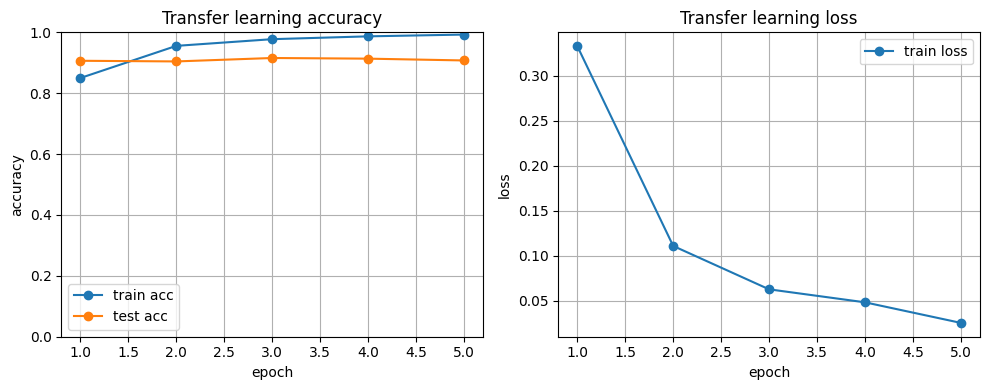

In [34]:
# ---------- 8) 画曲线 ----------
epochs_axis = range(1, num_epochs_tl + 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, train_accs_tl, marker="o", label="train acc")
plt.plot(epochs_axis, test_accs_tl, marker="o", label="test acc")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title("Transfer learning accuracy")
plt.subplot(1, 2, 2)
plt.plot(epochs_axis, train_losses_tl, marker="o", label="train loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.grid(True)
plt.title("Transfer learning loss")
plt.tight_layout()
plt.show()
